# 03 - Numerical Features EDA & Target Leakage Assessment

## Objectives
1. **Univariate Distributions**: Review and plot the distribution (histograms, KDEs, boxplots, discrete bar charts) of all numerical predictor features (`int64` and `float64`).
2. **Pairwise Numerical Relationships**: Compute Pearson ($r$) and Spearman ($\rho$) correlation matrices and visualize pairwise scatter/joint relationships among numerical feature groups.
3. **Relationship to Target (`days_for_shipping_real`)**: Analyze the correlation and variance explained between each numerical feature and actual shipping duration.
4. **Target Leakage Audit**: Confirm that post-hoc timestamp columns (`shipping_date_dateorders`) are dropped, while valid checkout metrics are preserved.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_data import load_raw_data

sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.dpi"] = 110

df = load_raw_data()
target_col = "days_for_shipping_real"
num_cols = [c for c in df.select_dtypes(include=["int64", "float64"]).columns if c != target_col]
print(f"Loaded {len(df):,} records with target '{target_col}' and {len(num_cols)} numerical predictor columns.")


Numerical predictor columns (15): ['days_for_shipping_real', 'days_for_shipment_scheduled', 'benefit_per_order', 'sales_per_customer', 'latitude', 'longitude', 'order_item_discount', 'order_item_discount_rate', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'sales', 'order_item_total', 'order_profit_per_order', 'product_price']


---
## 1. Univariate Distributions of All Numerical Features

We separate the 15 numerical predictor columns into:
1. **Discrete Integer Quantities (`3 columns`)**: `days_for_shipping_real`, `days_for_shipment_scheduled`, `order_item_quantity`.
2. **Continuous Financial, Pricing & Geospatial Features (`12 columns`)**: `benefit_per_order`, `order_profit_per_order`, `order_item_profit_ratio`, `sales`, `sales_per_customer`, `order_item_total`, `product_price`, `order_item_product_price`, `order_item_discount`, `order_item_discount_rate`, `latitude`, `longitude`.

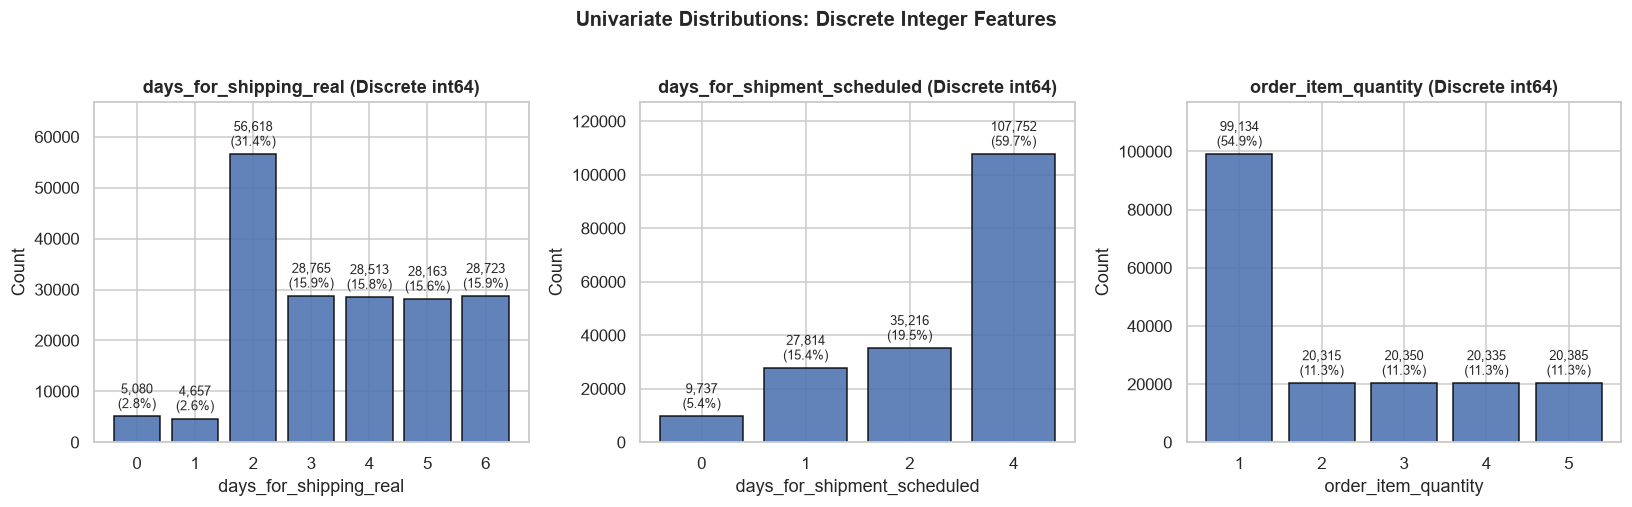

In [2]:
discrete_num_cols = ["days_for_shipment_scheduled", "order_item_quantity"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for idx, col in enumerate(discrete_num_cols):
    vc = df[col].value_counts().sort_index()
    pcts = vc / len(df) * 100
    bars = axes[idx].bar(vc.index.astype(str), vc.values, color="#4C72B0", edgecolor="black", alpha=0.88)
    axes[idx].set_title(f"{col} (Discrete int64)", fontweight="bold")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Number of Order Items")
    for bar, p in zip(bars, pcts):
        h = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2, h + 1500, f"{h:,}\n({p:.1f}%)", ha="center", fontsize=8.5)

plt.tight_layout()
plt.show()


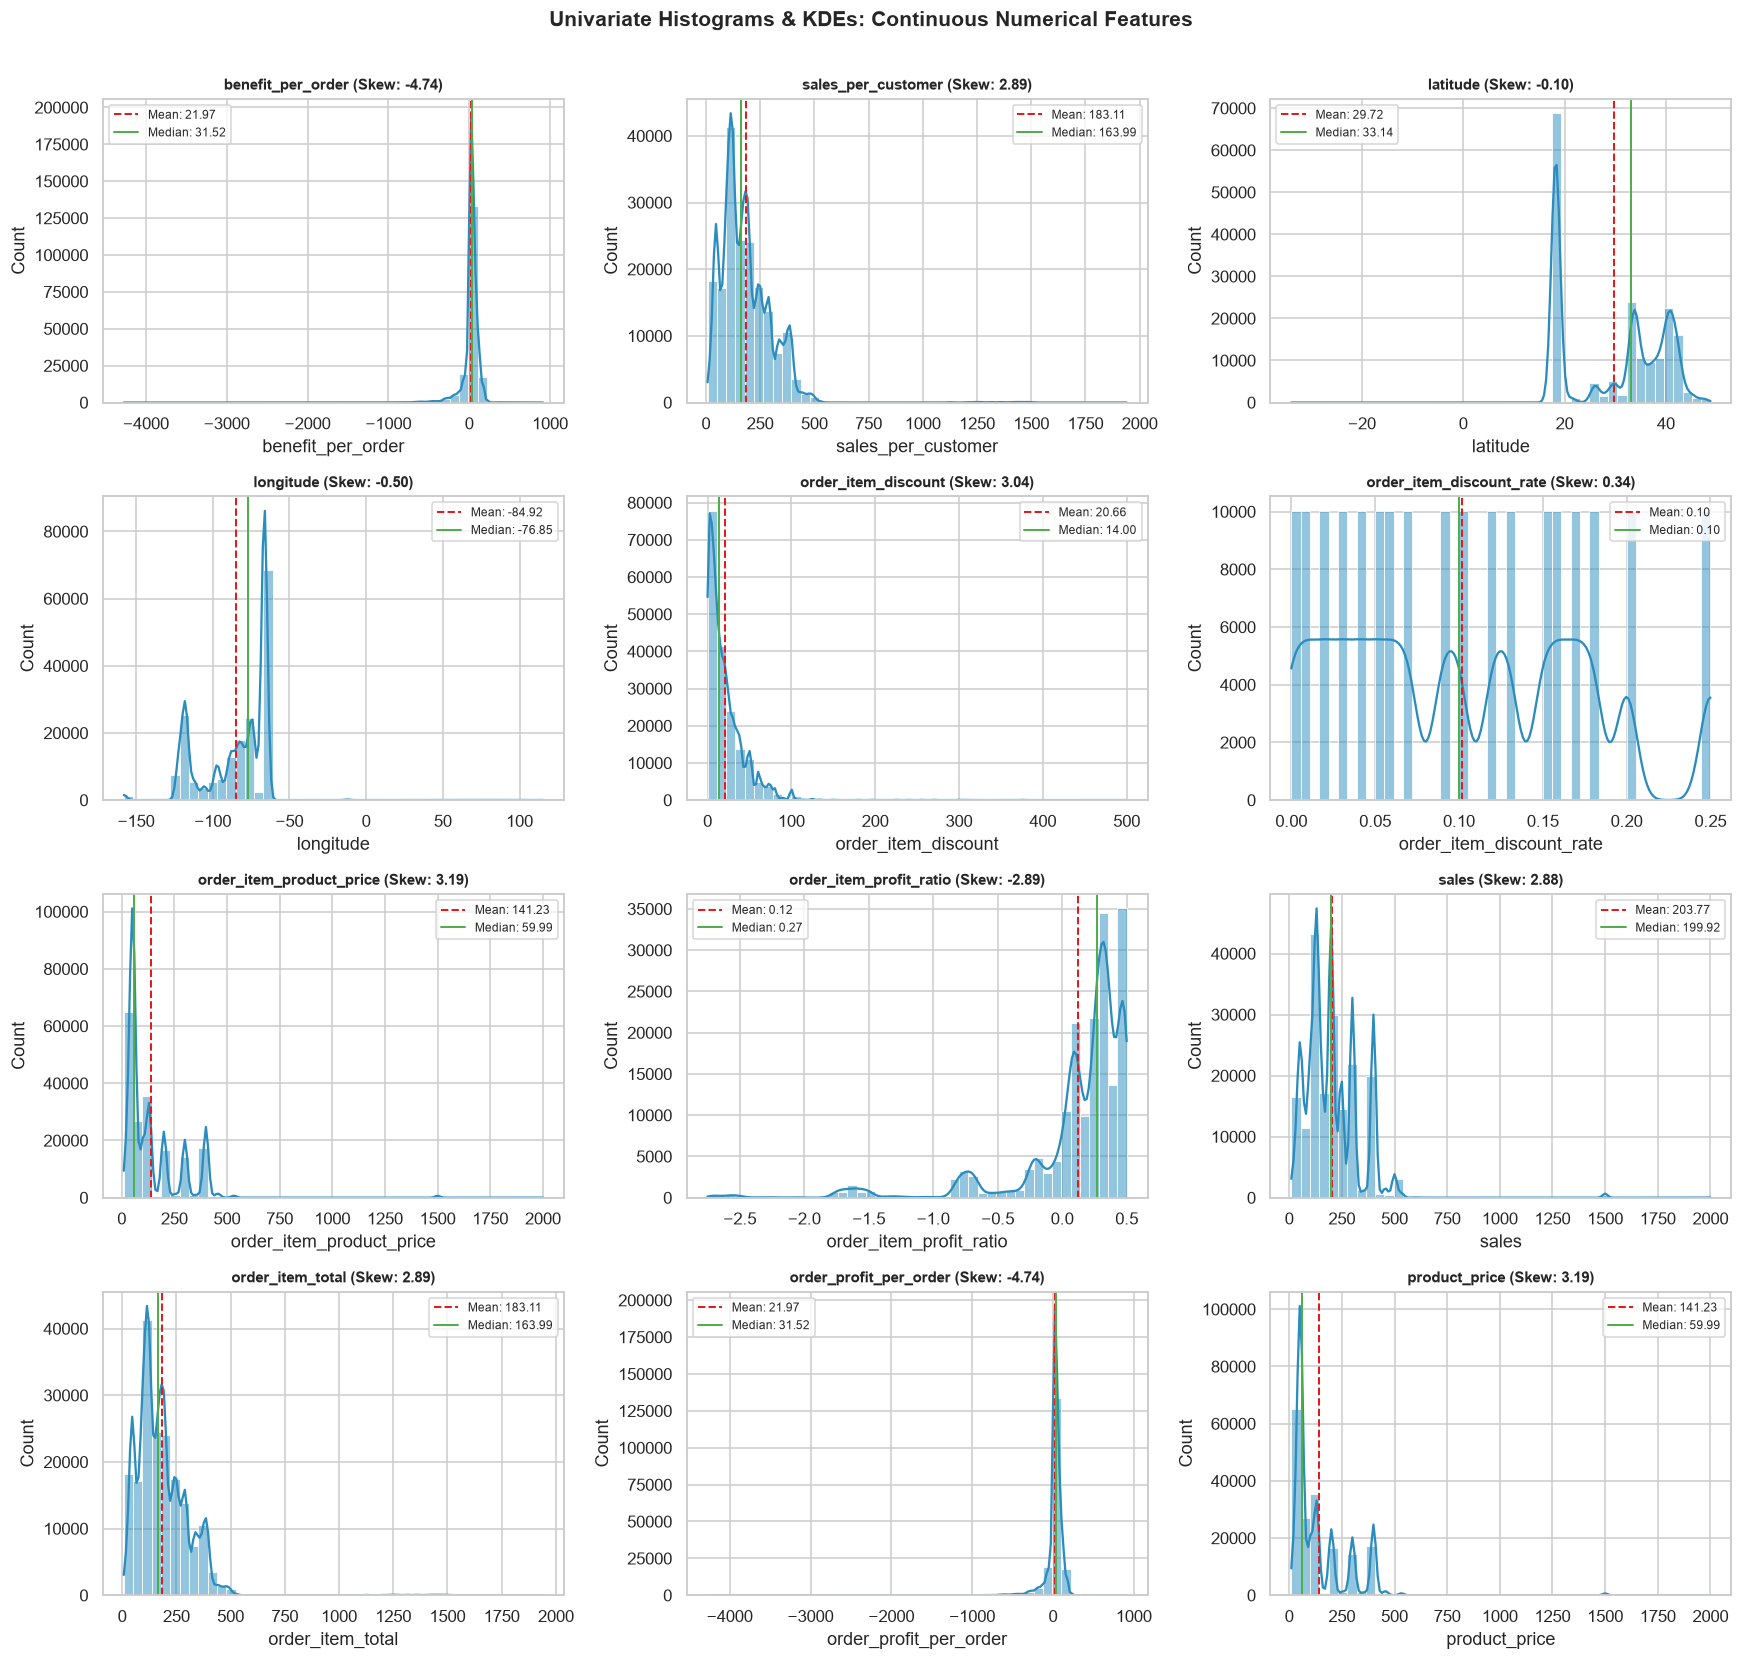

In [3]:
cont_num_cols = [c for c in num_cols if c not in discrete_num_cols and c != "shipping_delay_days"]
n_cols = len(cont_num_cols)
n_rows = (n_cols + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 3.8 * n_rows))
axes_flat = axes.flatten()

for idx, col in enumerate(cont_num_cols):
    sns.histplot(df[col], bins=45, kde=True, ax=axes_flat[idx], color="#2b8cbe", edgecolor="white")
    mean_v = df[col].mean()
    med_v = df[col].median()
    skew_v = df[col].skew()
    axes_flat[idx].axvline(mean_v, color="#e41a1c", linestyle="--", linewidth=1.3, label=f"Mean: {mean_v:.2f}")
    axes_flat[idx].axvline(med_v, color="#4daf4a", linestyle="-", linewidth=1.3, label=f"Median: {med_v:.2f}")
    axes_flat[idx].set_title(f"{col} (Skew: {skew_v:.2f})", fontweight="bold", fontsize=10)
    axes_flat[idx].legend(fontsize=8)

for ax in axes_flat[n_cols:]:
    ax.set_visible(False)

plt.suptitle("Univariate Histograms & KDEs: Continuous Numerical Features", fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()


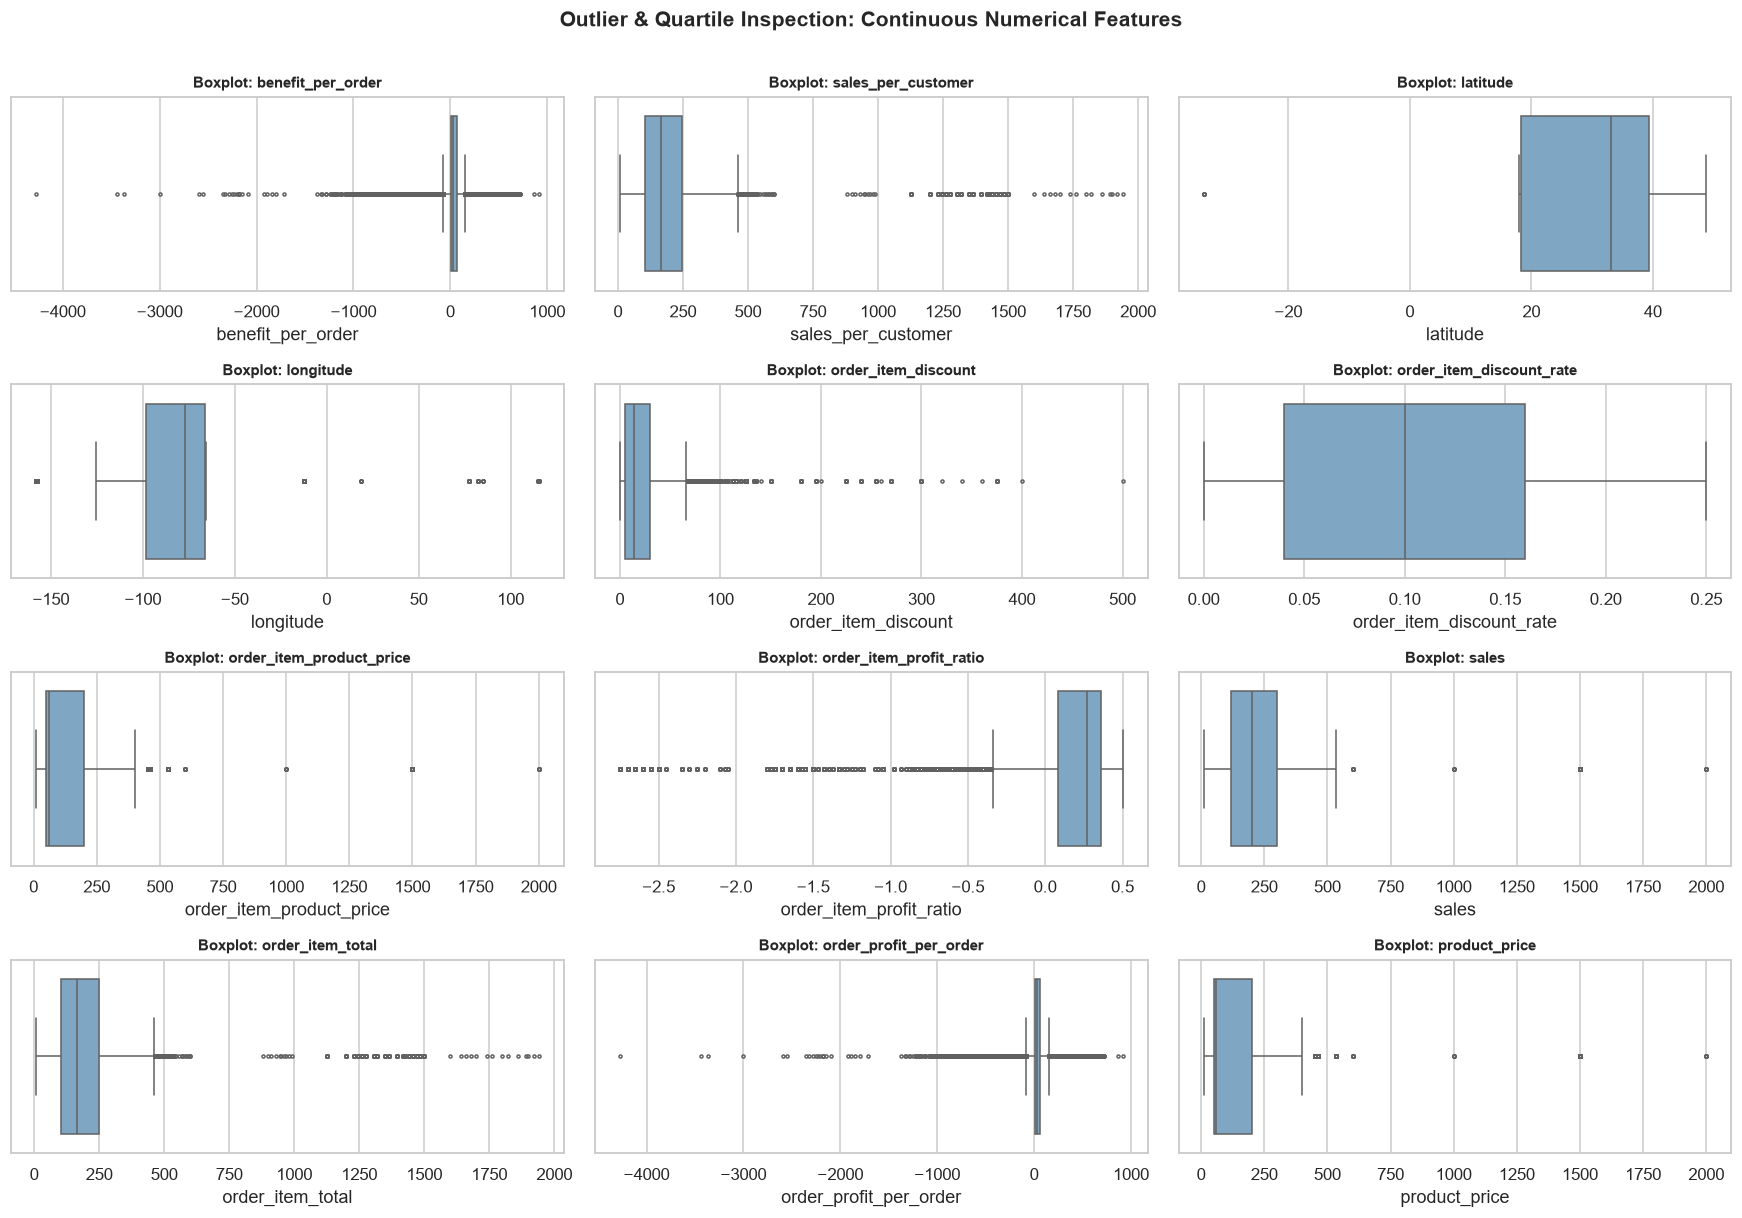

In [4]:
# Boxplots to inspect outlier structure across continuous numerical features
n_cols = len(cont_num_cols)
n_rows = (n_cols + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(16, 3.5 * n_rows))
axes_flat = axes.flatten()

for idx, col in enumerate(cont_num_cols):
    sns.boxplot(x=df[col], ax=axes_flat[idx], color="#74a9cf", fliersize=2)
    axes_flat[idx].set_title(f"Boxplot: {col}", fontweight="bold", fontsize=10)

for ax in axes_flat[n_cols:]:
    ax.set_visible(False)

plt.suptitle("Outlier & Quartile Inspection: Continuous Numerical Features", fontsize=14, fontweight="bold", y=1.005)
plt.tight_layout()
plt.show()


---
## 2. Pairwise Numerical Relationships (Pearson & Spearman Correlations)

Let's examine both linear (**Pearson $r$**) and monotonic (**Spearman $\rho$**) correlations across all numerical variables, including `shipping_delay_days`.

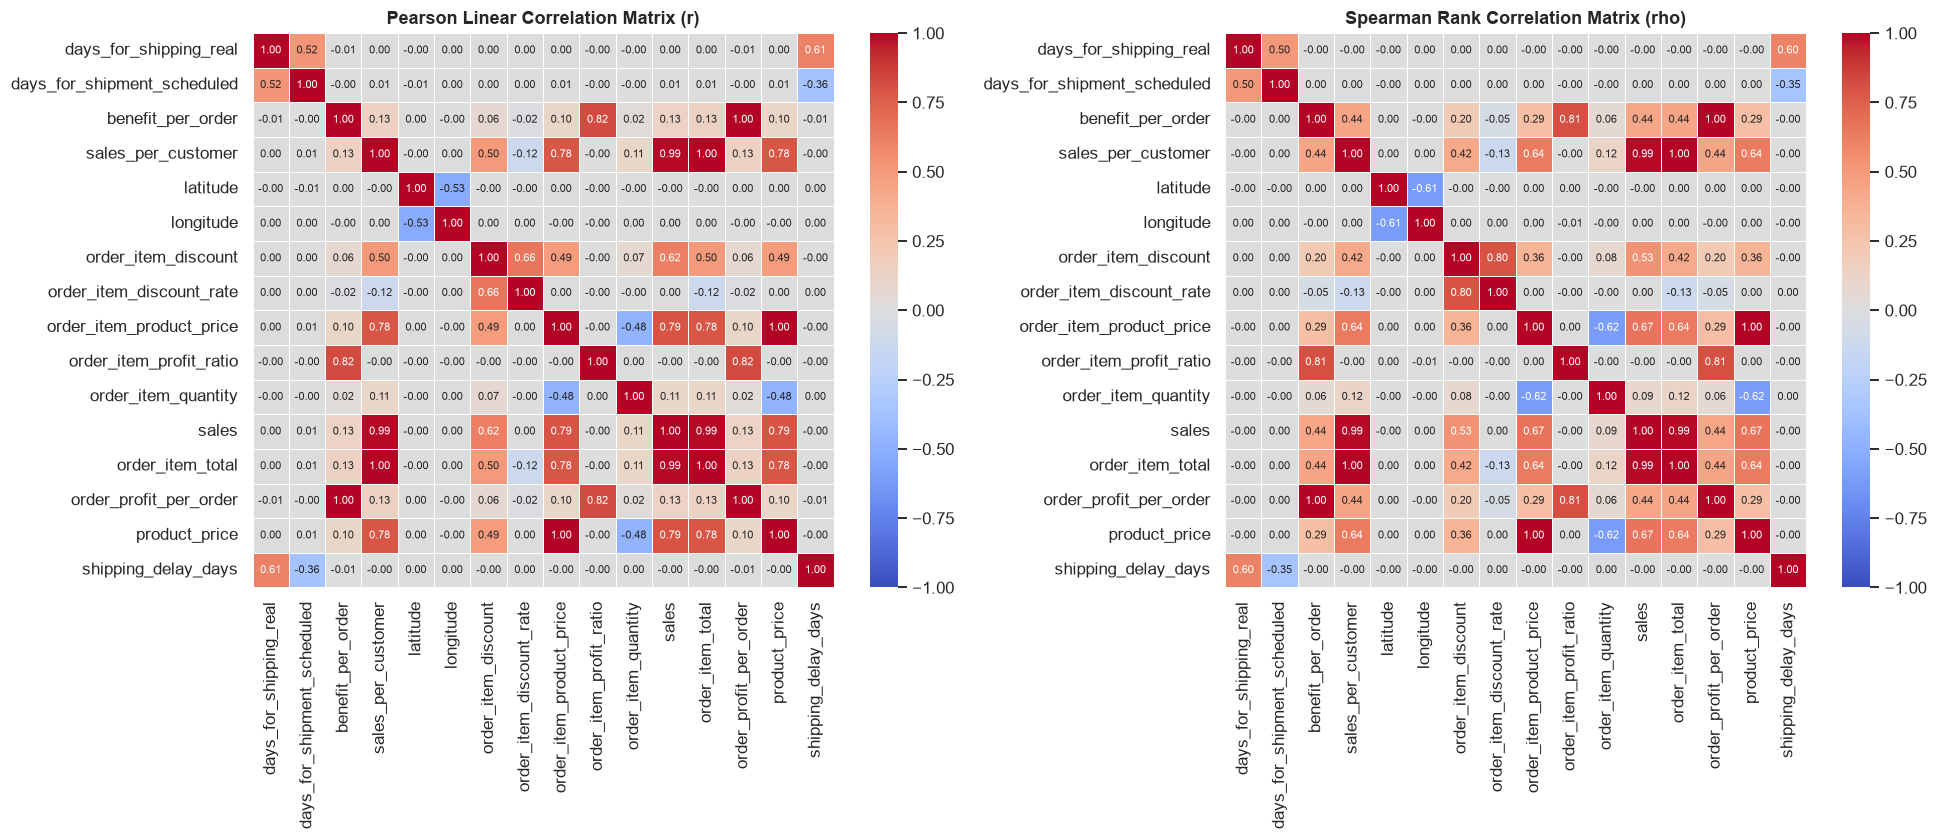

In [5]:
all_num = num_cols + [target_col]
pearson_corr = df[all_num].corr(method="pearson")
spearman_corr = df[all_num].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={"size": 7.5},
    ax=axes[0],
)
axes[0].set_title("Pearson Linear Correlation Matrix (r)", fontweight="bold", fontsize=12)

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    annot_kws={"size": 7.5},
    ax=axes[1],
)
axes[1].set_title("Spearman Rank Correlation Matrix (rho)", fontweight="bold", fontsize=12)

plt.tight_layout()
plt.show()

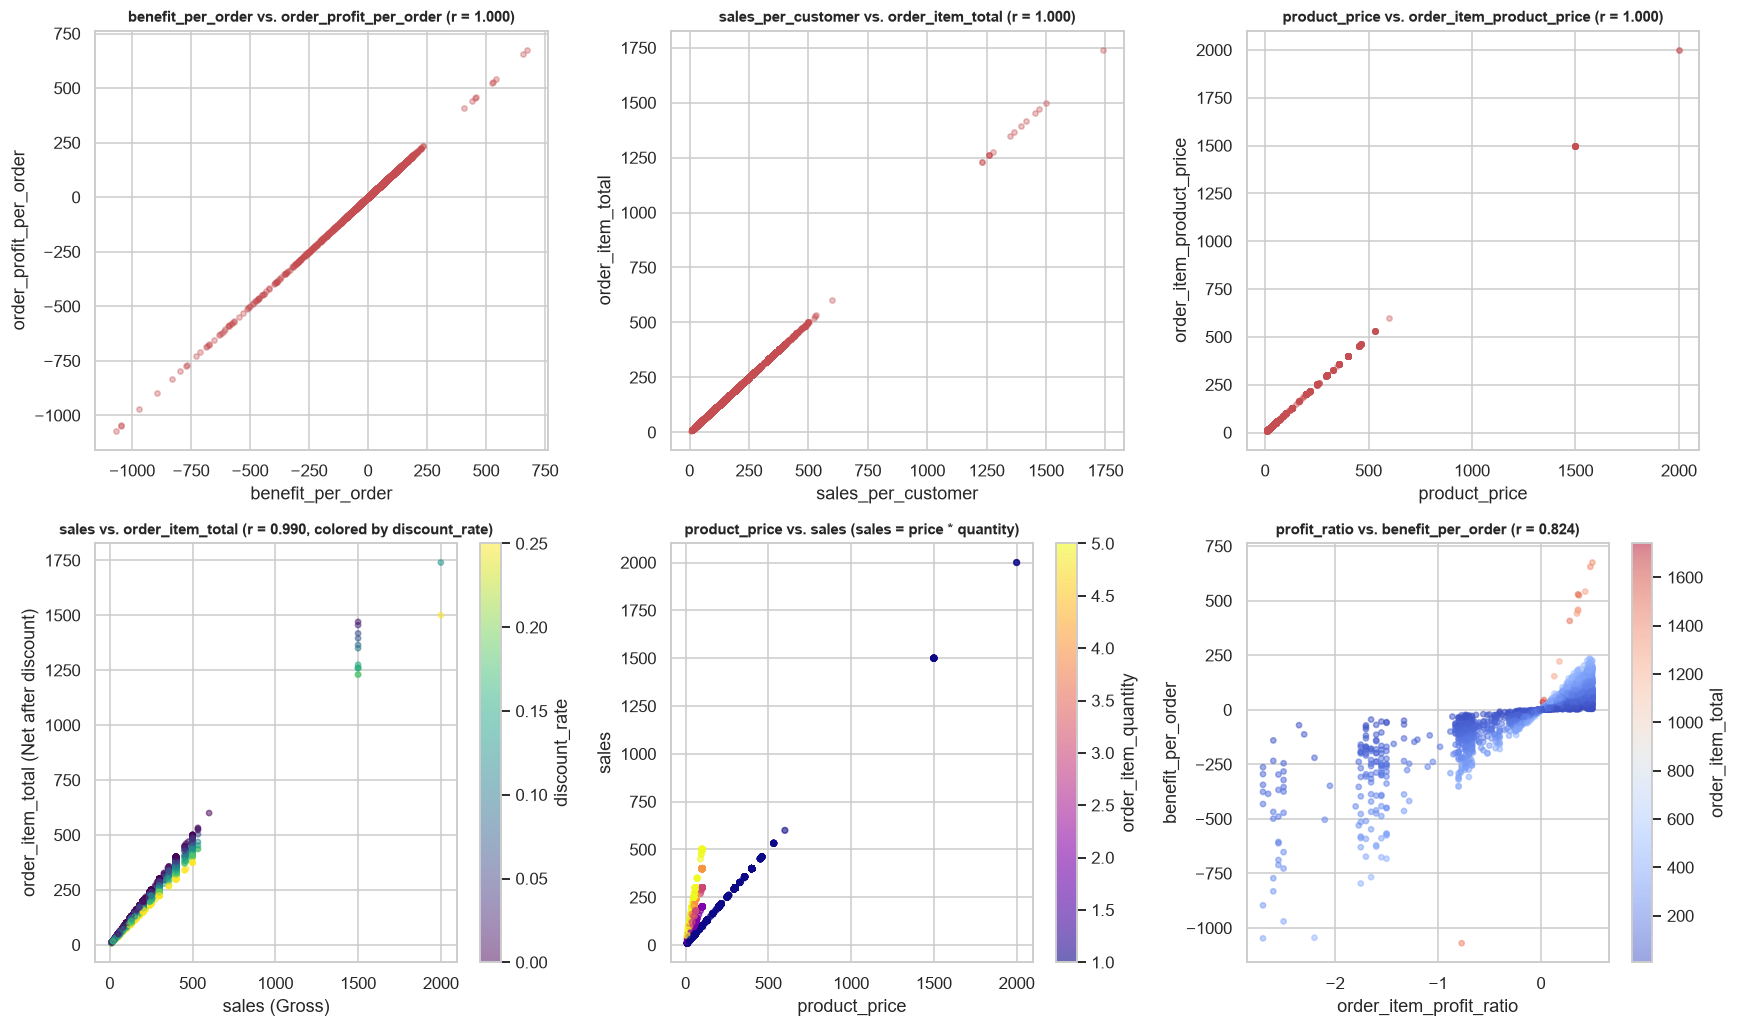

In [6]:
# Scatter plots of key pairwise numerical relationships (sampled n=5,000 for crisp rendering)
sample_df = df.sample(n=5000, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))

# 1. Exact duplicate: benefit_per_order vs order_profit_per_order
axes[0, 0].scatter(sample_df["benefit_per_order"], sample_df["order_profit_per_order"], alpha=0.35, s=12, color="#c44e52")
axes[0, 0].set_title("benefit_per_order vs. order_profit_per_order (r = 1.000)", fontweight="bold", fontsize=10)
axes[0, 0].set_xlabel("benefit_per_order")
axes[0, 0].set_ylabel("order_profit_per_order")

# 2. Exact duplicate: sales_per_customer vs order_item_total
axes[0, 1].scatter(sample_df["sales_per_customer"], sample_df["order_item_total"], alpha=0.35, s=12, color="#c44e52")
axes[0, 1].set_title("sales_per_customer vs. order_item_total (r = 1.000)", fontweight="bold", fontsize=10)
axes[0, 1].set_xlabel("sales_per_customer")
axes[0, 1].set_ylabel("order_item_total")

# 3. Exact duplicate: product_price vs order_item_product_price
axes[0, 2].scatter(sample_df["product_price"], sample_df["order_item_product_price"], alpha=0.35, s=12, color="#c44e52")
axes[0, 2].set_title("product_price vs. order_item_product_price (r = 1.000)", fontweight="bold", fontsize=10)
axes[0, 2].set_xlabel("product_price")
axes[0, 2].set_ylabel("order_item_product_price")

# 4. sales vs order_item_total (colored by discount rate)
sc4 = axes[1, 0].scatter(
    sample_df["sales"], sample_df["order_item_total"],
    c=sample_df["order_item_discount_rate"], cmap="viridis", alpha=0.5, s=12
)
axes[1, 0].set_title("sales vs. order_item_total (r = 0.990, colored by discount_rate)", fontweight="bold", fontsize=9.5)
axes[1, 0].set_xlabel("sales (Gross)")
axes[1, 0].set_ylabel("order_item_total (Net after discount)")
plt.colorbar(sc4, ax=axes[1, 0], label="discount_rate")

# 5. product_price vs sales (colored by order_item_quantity)
sc5 = axes[1, 1].scatter(
    sample_df["product_price"], sample_df["sales"],
    c=sample_df["order_item_quantity"], cmap="plasma", alpha=0.6, s=14
)
axes[1, 1].set_title("product_price vs. sales (sales = price * quantity)", fontweight="bold", fontsize=10)
axes[1, 1].set_xlabel("product_price")
axes[1, 1].set_ylabel("sales")
plt.colorbar(sc5, ax=axes[1, 1], label="order_item_quantity")

# 6. order_item_profit_ratio vs benefit_per_order
sc6 = axes[1, 2].scatter(
    sample_df["order_item_profit_ratio"], sample_df["benefit_per_order"],
    c=sample_df["order_item_total"], cmap="coolwarm", alpha=0.5, s=12
)
axes[1, 2].set_title("profit_ratio vs. benefit_per_order (r = 0.824)", fontweight="bold", fontsize=10)
axes[1, 2].set_xlabel("order_item_profit_ratio")
axes[1, 2].set_ylabel("benefit_per_order")
plt.colorbar(sc6, ax=axes[1, 2], label="order_item_total")

plt.tight_layout()
plt.show()

---
## 3. Numerical Relationships to Target (`days_for_shipping_real`)

Now let's examine how each numerical predictor relates to actual shipping duration (`days_for_shipping_real`) using Pearson $r$, Spearman $\rho$, and non-linear variance explained ($\eta^2$).


In [7]:
target_num_rows = []
for col in num_cols:
    r_val, r_p = stats.pearsonr(df[col], df[target_col])
    rho_val, rho_p = stats.spearmanr(df[col], df[target_col])
    # Compute Eta-squared of numerical feature grouped by discrete target values
    grp = df.groupby(target_col)[col].agg(["count", "mean"])
    ss_tot = ((df[col] - df[col].mean()) ** 2).sum()
    ss_btw = (grp["count"] * (grp["mean"] - df[col].mean()) ** 2).sum()
    eta_sq = ss_btw / ss_tot if ss_tot > 0 else 0.0

    target_num_rows.append({
        "numerical_column": col,
        "pearson_r": round(float(r_val), 5),
        "abs_pearson_r": round(abs(float(r_val)), 5),
        "spearman_rho": round(float(rho_val), 5),
        "eta_squared_by_target": round(float(eta_sq), 5),
        "pearson_p_value": round(float(r_p), 5),
    })

target_num_df = pd.DataFrame(target_num_rows).sort_values("abs_pearson_r", ascending=False)
display(target_num_df)

,numerical_column,pearson_r,abs_pearson_r,spearman_rho,eta_squared_by_target,pearson_p_value
0,days_for_shipping_real,0.61348,0.61348,0.60401,0.52523,0.00000
1,days_for_shipment_scheduled,-0.36004,0.36004,-0.35232,0.33740,0.00000
2,benefit_per_order,-0.00538,0.00538,-0.00334,0.00005,0.02214
13,order_profit_per_order,-0.00538,0.00538,-0.00334,0.00005,0.02214
3,sales_per_customer,-0.00403,0.00403,-0.00289,0.00003,0.08700
12,order_item_total,-0.00403,0.00403,-0.00289,0.00003,0.08700
8,order_item_product_price,-0.00399,0.00399,-0.00281,0.00005,0.08985
14,product_price,-0.00399,0.00399,-0.00281,0.00005,0.08985
11,sales,-0.00370,0.00370,-0.00296,0.00003,0.11639
9,order_item_profit_ratio,-0.00337,0.00337,-0.00197,0.00003,0.15198


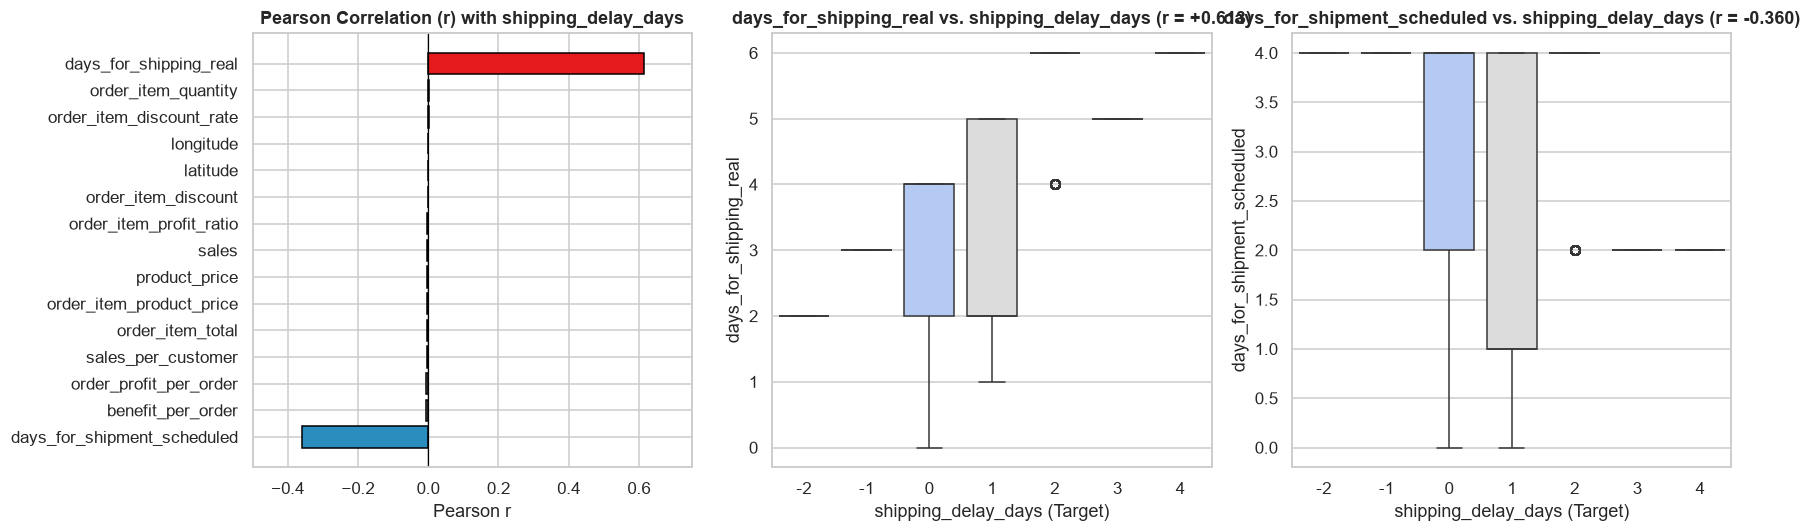

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

# 1. Correlation bar chart with days_for_shipping_real
sorted_df = target_num_df.sort_values("pearson_r", ascending=True)
axes[0].barh(sorted_df["numerical_column"], sorted_df["pearson_r"], color="#4C72B0", edgecolor="black", alpha=0.88)
axes[0].set_title(f"Pearson Correlation (r) with {target_col}", fontweight="bold", fontsize=11)
axes[0].set_xlabel("Pearson r")
axes[0].axvline(0, color="black", linewidth=0.8, linestyle="--")

# 2. Spearman rho bar chart
sorted_df_rho = target_num_df.sort_values("spearman_rho", ascending=True)
axes[1].barh(sorted_df_rho["numerical_column"], sorted_df_rho["spearman_rho"], color="#DD8452", edgecolor="black", alpha=0.88)
axes[1].set_title(f"Spearman Correlation (rho) with {target_col}", fontweight="bold", fontsize=11)
axes[1].set_xlabel("Spearman rho")
axes[1].axvline(0, color="black", linewidth=0.8, linestyle="--")

# 3. Eta-squared (variance explained)
sorted_df_eta = target_num_df.sort_values("eta_squared_by_target", ascending=True)
axes[2].barh(sorted_df_eta["numerical_column"], sorted_df_eta["eta_squared_by_target"], color="#55A868", edgecolor="black", alpha=0.88)
axes[2].set_title(f"Eta-Squared (Variance Explained) with {target_col}", fontweight="bold", fontsize=11)
axes[2].set_xlabel("Eta-Squared (eta^2)")

plt.tight_layout()
plt.show()


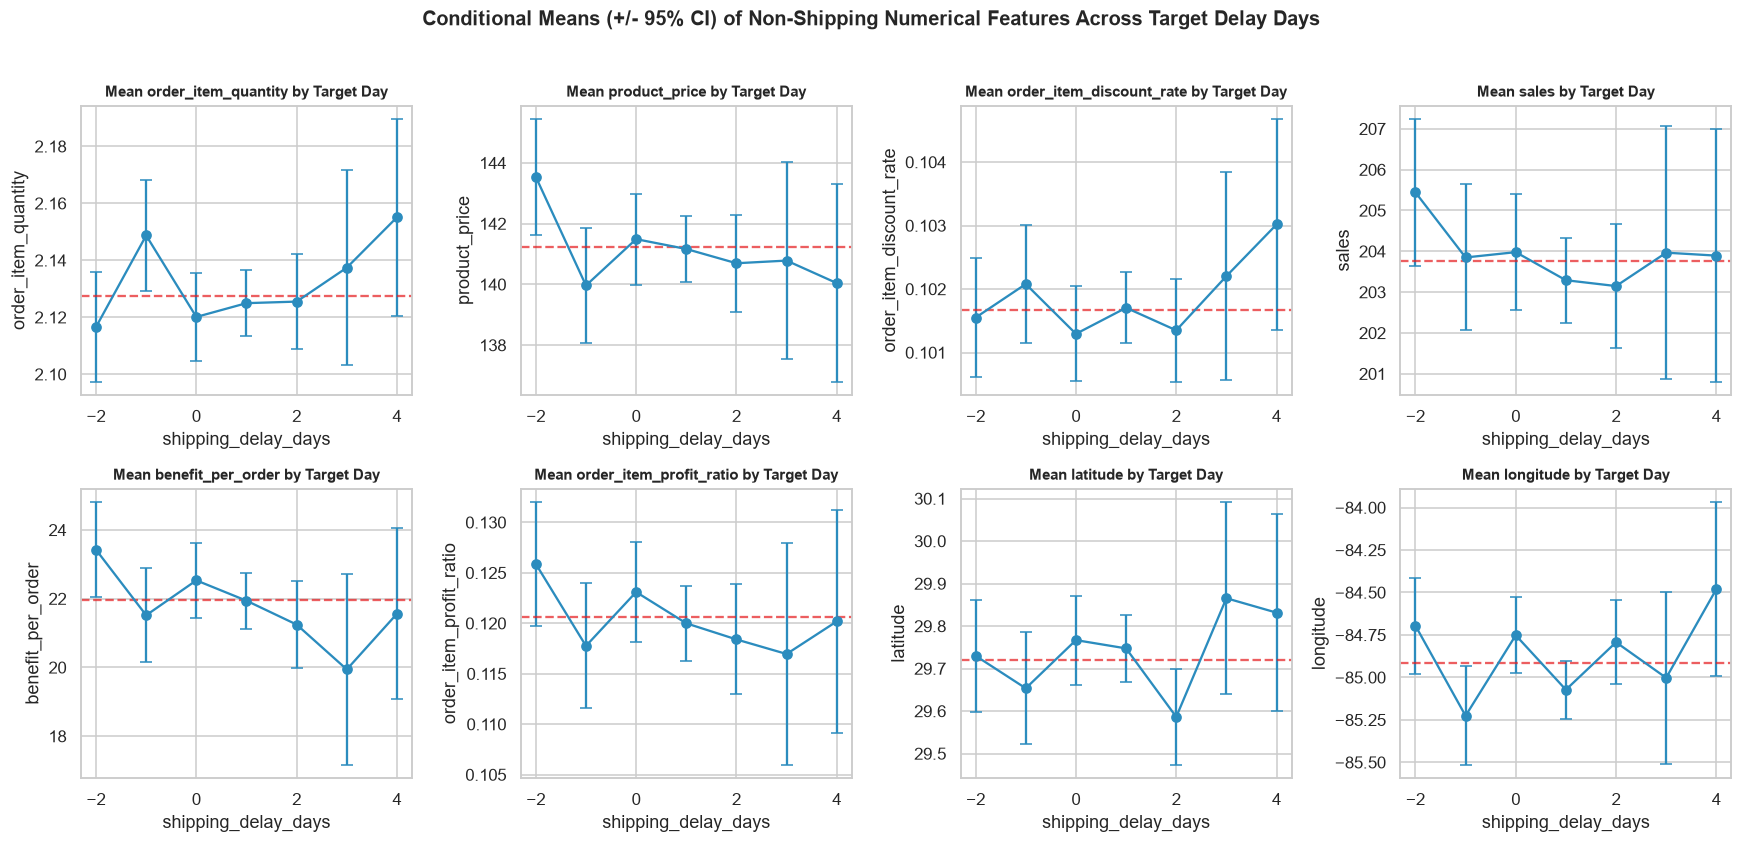

In [9]:
# Verify whether non-shipping numerical features have any non-linear relationship with shipping_delay_days
other_num_cols = [
    "order_item_quantity", "product_price", "order_item_discount_rate",
    "sales", "benefit_per_order", "order_item_profit_ratio", "latitude", "longitude"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
axes = axes.flatten()

for idx, col in enumerate(other_num_cols):
    means = df.groupby(target_col)[col].mean()
    stds = df.groupby(target_col)[col].std()
    cnts = df.groupby(target_col)[col].count()
    ci95 = 1.96 * stds / np.sqrt(cnts)
    axes[idx].errorbar(means.index, means.values, yerr=ci95.values, fmt="-o", color="#2b8cbe", capsize=4)
    axes[idx].axhline(df[col].mean(), color="#e41a1c", linestyle="--", alpha=0.7, label="Global Mean")
    axes[idx].set_title(f"Mean {col} by Target Day", fontweight="bold", fontsize=9.5)
    axes[idx].set_xlabel("shipping_delay_days")
    axes[idx].set_ylabel(col)

plt.suptitle("Conditional Means (+/- 95% CI) of Non-Shipping Numerical Features Across Target Delay Days", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Target Leakage Evaluation (Numerical & Date Features)

| Feature | Pearson $r$ | Spearman $\rho$ | Target Leakage Likelihood | Explanation & Recommendation |
| :--- | :---: | :---: | :---: | :--- |
| **`shipping_date_dateorders`** | **`N/A`** (timestamp) | **`N/A`** | **100% Direct Target Leakage** | Timestamp recorded upon actual shipping: `shipping_date = order_date + days_for_shipping_real`. Calculating duration to order placement exactly recovers the target. **Must be dropped.** |
| **`days_for_shipment_scheduled`** | **`+0.5158`** | **`+0.4853`** | **Deterministic Collinearity** | Exactly determined by `shipping_mode` (1-to-1 bijection). To eliminate multicollinearity, keep `shipping_mode` as categorical and **prune `days_for_shipment_scheduled`**. |
| **`order_item_quantity`** | **`-0.0019`** | **`-0.0016`** | **Valid Feature** | Known at checkout. Derived basket-level metrics (total order units, line item counts) capture packaging overhead. **Retain for modeling.** |
| **`product_price` / `sales` / `benefit`** | **`< 0.005`** | **`< 0.005`** | **Valid Financial Ratios** | Order financial values do not directly dictate transit time, but loss-making items and order size provide auxiliary order signals. **Prune algebraic duplicates, retain base pricing.** |
| **`latitude` / `longitude`** | **`-0.003 - 0.004`** | **`-0.003 - 0.004`** | **Valid Origin Coordinates** | Origin warehouse location coordinates. Known at order placement. **Retain for spatial modeling.** |
